# Model Checking

After running an MCMC simulation, `sample` returns a `MultiTrace` object containing the samples for all the stochastic and deterministic random variables. The final step in Bayesian computation is model checking, which uses information from the sample to ensure that inferences derived from them are valid.

There are two components to model checking:

1. Convergence diagnostics
2. Goodness of fit

Convergence diagnostics are intended to detect lack of convergence in the Markov chain Monte Carlo sample; it is used to ensure that you have not halted your sampling too early. However, a converged model is not guaranteed to be a good model.

Goodness of fit, is used to check the internal validity of the model, by comparing predictions from the model to the data used to fit the model.

## Convergence Diagnostics

Valid inferences from sequences of MCMC samples are based on the
assumption that the samples are derived from the true posterior
distribution of interest. Theory guarantees this condition as the number
of iterations approaches infinity. It is important, therefore, to
determine the **minimum number of samples** required to ensure a reasonable
approximation to the target posterior density. Unfortunately, no
universal threshold exists across all problems, so convergence must be
assessed independently each time MCMC estimation is performed. The
procedures for verifying convergence are collectively known as
*convergence diagnostics*.

The most common approach to diagnosing convergence is a
**statistical** approach, which uses metrics related the statistical properties of the observed chain. Reliance on the sample alone restricts such convergence
criteria to **heuristics**. As a result, convergence cannot be guaranteed.
Although evidence for lack of convergence using statistical convergence
diagnostics will correctly imply lack of convergence in the chain, the
absence of such evidence will not *guarantee* convergence in the chain.
Nevertheless, negative results for one or more criteria may provide some
measure of assurance to users that their sample will provide valid
inferences.

For most simple models, convergence will occur quickly, sometimes within
a the first several hundred iterations, after which all remaining
samples of the chain may be used to calculate posterior quantities. For
more complex models, convergence requires a significantly longer burn-in
period; sometimes orders of magnitude more samples are needed.
Frequently, lack of convergence will be caused by **poor mixing**.
Recall that *mixing* refers to the degree to which the Markov
chain explores the support of the posterior distribution. Poor mixing
may stem from inappropriate proposals (if one is using the
Metropolis-Hastings sampler) or from attempting to estimate models with
highly correlated variables.

## Example: Rat growth

This example is taken from section 6 of Gelfand et al (1990), and concerns 30 young rats whose weights were measured weekly for five weeks. So, $Y_{i,j}$ is the weight of the $i$th rat measured at age $x_j$.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter('ignore')
import arviz as az
sns.set_context('notebook')

import pymc as pm

In [2]:
ages = 8.0, 15.0, 22.0, 29.0, 36.0
rat_weights = pd.DataFrame(np.array([151, 199, 246, 283, 320,
                     145, 199, 249, 293, 354,
                     147, 214, 263, 312, 328,
                     155, 200, 237, 272, 297,
                     135, 188, 230, 280, 323,
                     159, 210, 252, 298, 331,
                     141, 189, 231, 275, 305,
                     159, 201, 248, 297, 338,
                     177, 236, 285, 350, 376,
                     134, 182, 220, 260, 296,
                     160, 208, 261, 313, 352,
                     143, 188, 220, 273, 314,
                     154, 200, 244, 289, 325,
                     171, 221, 270, 326, 358,
                     163, 216, 242, 281, 312,
                     160, 207, 248, 288, 324,
                     142, 187, 234, 280, 316,
                     156, 203, 243, 283, 317,
                     157, 212, 259, 307, 336,
                     152, 203, 246, 286, 321,
                     154, 205, 253, 298, 334,
                     139, 190, 225, 267, 302,
                     146, 191, 229, 272, 302,
                     157, 211, 250, 285, 323,
                     132, 185, 237, 286, 331,
                     160, 207, 257, 303, 345,
                     169, 216, 261, 295, 333,
                     157, 205, 248, 289, 316,
                     137, 180, 219, 258, 291,
                     153, 200, 244, 286, 324]).reshape(30,5).astype(int),
                          columns=ages)
rat_weights.head()

,8.0,15.0,22.0,29.0,36.0
0,151,199,246,283,320
1,145,199,249,293,354
2,147,214,263,312,328
3,155,200,237,272,297
4,135,188,230,280,323


In [3]:
rat_weights.shape

(30, 5)

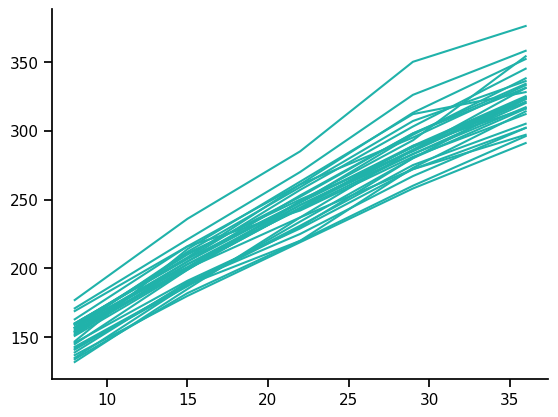

In [4]:
ax = rat_weights.T.plot(legend=False, color='LightSeaGreen')
sns.despine()


$$Y_{i,j} \sim \text{Normal}(\alpha_i + \beta_i x_j  , \sigma)$$

$$\alpha_i \sim \text{Normal}(m_a, s_a)$$

$$\beta_i \sim \text{Normal}(m_b , s_b)$$

In [22]:
rat_weights

,8.0,15.0,22.0,29.0,36.0
0,151,199,246,283,320
1,145,199,249,293,354
2,147,214,263,312,328
3,155,200,237,272,297
4,135,188,230,280,323
5,159,210,252,298,331
6,141,189,231,275,305
7,159,201,248,297,338
8,177,236,285,350,376
9,134,182,220,260,296


In [24]:
pd.melt(rat_weights.reset_index(), id_vars='index',  var_name='weeks', value_name='weight')

,index,weeks,weight
0,0,8.0,151
1,1,8.0,145
2,2,8.0,147
3,3,8.0,155
4,4,8.0,135
...,...,...,...
145,25,36.0,345
146,26,36.0,333
147,27,36.0,316
148,28,36.0,291


In [5]:
n_rats = rat_weights.shape[0]
rat_index, age, weight = pd.melt(rat_weights.reset_index(), id_vars='index').values.astype(int).T


In [6]:
age, weight, rat_index

(array([ 8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,
         8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8,  8, 15, 15, 15, 15,
        15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15,
        15, 15, 15, 15, 15, 15, 15, 15, 15, 22, 22, 22, 22, 22, 22, 22, 22,
        22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22, 22,
        22, 22, 22, 22, 22, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29,
        29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29, 29,
        29, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36,
        36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36, 36]),
 array([151, 145, 147, 155, 135, 159, 141, 159, 177, 134, 160, 143, 154,
        171, 163, 160, 142, 156, 157, 152, 154, 139, 146, 157, 132, 160,
        169, 157, 137, 153, 199, 199, 214, 200, 188, 210, 189, 201, 236,
        182, 208, 188, 200, 221, 216, 207, 187, 203, 212, 203, 205, 190,
        191, 211, 185, 207, 216, 2

In [7]:
rat_weights.head(10)

,8.0,15.0,22.0,29.0,36.0
0,151,199,246,283,320
1,145,199,249,293,354
2,147,214,263,312,328
3,155,200,237,272,297
4,135,188,230,280,323
5,159,210,252,298,331
6,141,189,231,275,305
7,159,201,248,297,338
8,177,236,285,350,376
9,134,182,220,260,296


In [8]:
rat_cat = np.arange(30)

## Option 1

In [25]:
coords = {"rats_names": rat_cat, "rat_index":rat_cat[rat_index]}

with pm.Model(coords=coords) as rat_model1:

    # Hierarchical means
    m_a = pm.Normal('m_a', 150, sigma=100)
    m_b = pm.Normal('m_b', 20, sigma=10)

    # Hierarchical st.devs
    s_a = pm.HalfCauchy('s_a', 1)
    s_b = pm.HalfCauchy('s_b', 1)

    # Intercepts and slopes
    α = pm.Normal('α', m_a, sigma=s_a, dims='rats_names')
    β = pm.Normal('β', m_b, sigma=s_b, dims='rats_names')

    # Expected values
    μ = α[rat_index] + β[rat_index]*age

    # Likelihood function
    σ = pm.HalfCauchy('σ', 1)
    y = pm.Normal('y', μ, sigma=σ, observed=weight, dims = 'rat_index')

    rat_trace = pm.sample(5000, cores=2)

Output()

## Option 2

In [10]:

with pm.Model() as rat_model:

    # Hierarchical means
    m_a = pm.Normal('m_a', 150, sigma=100)
    m_b = pm.Normal('m_b', 20, sigma=10)

    # Hierarchical st.devs
    s_a = pm.HalfCauchy('s_a', 1)
    s_b = pm.HalfCauchy('s_b', 1)

    # Intercepts and slopes
    α = pm.Normal('α', m_a, sigma=s_a, shape=n_rats)
    β = pm.Normal('β', m_b, sigma=s_b, shape=n_rats)

    # Expected values
    μ = α[rat_index] + β[rat_index]*age

    # Likelihood function
    σ = pm.HalfCauchy('σ', 1)
    y = pm.Normal('y', μ, sigma=σ, observed=weight)


$$Y_{i,j} \sim \text{Normal}(\alpha_i + \beta_i x_j  , \sigma)$$

$$\alpha_i \sim \text{Normal}(m_a, s_a)$$

$$\beta_i \sim \text{Normal}(m_b , s_b)$$

$$ \sigma \sim HalfCauchy( 1) $$

$$ m_a \sim N(150, 100) $$
$$ m_b \sim N(20, 100) $$

$$ s_a \sim HalfCauchy(1) $$
$$ s_b \sim HalfCauchy(1) $$

Let's peek at a **directed acyclic graph (DAG)** of the model to make sure it looks right.

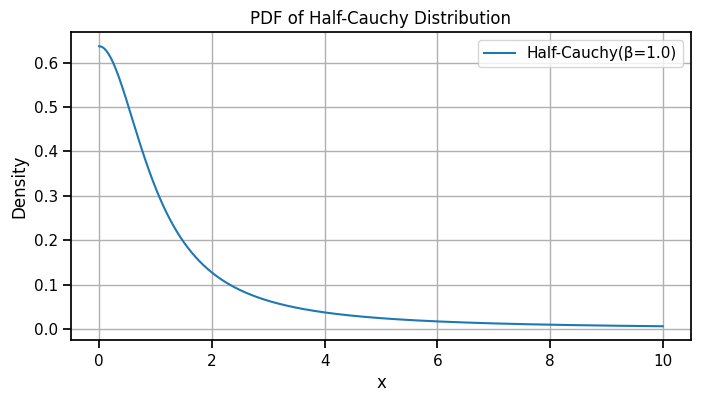

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import halfcauchy

# Parameters
beta = 1.0  # scale parameter
x = np.linspace(0.001, 10, 1000)  # avoid zero to prevent singularity

# Compute PDF
pdf = halfcauchy.pdf(x, scale=beta)

# Plot
plt.figure(figsize=(8, 4))
plt.plot(x, pdf, label=f'Half-Cauchy(β={beta})')
plt.title("PDF of Half-Cauchy Distribution")
plt.xlabel("x")
plt.ylabel("Density")
plt.grid(True)
plt.legend()
plt.show()

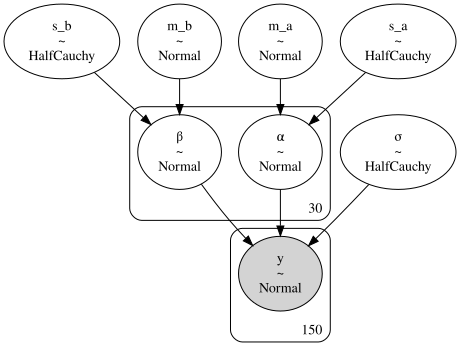

In [12]:
pm.model_to_graphviz(rat_model)

In [14]:
with rat_model:
    rat_trace = pm.sample(5000, cores=2)

Output()

array([[<Axes: title={'center': 'm_a'}>, <Axes: title={'center': 'm_a'}>],
       [<Axes: title={'center': 'm_b'}>, <Axes: title={'center': 'm_b'}>]],
      dtype=object)

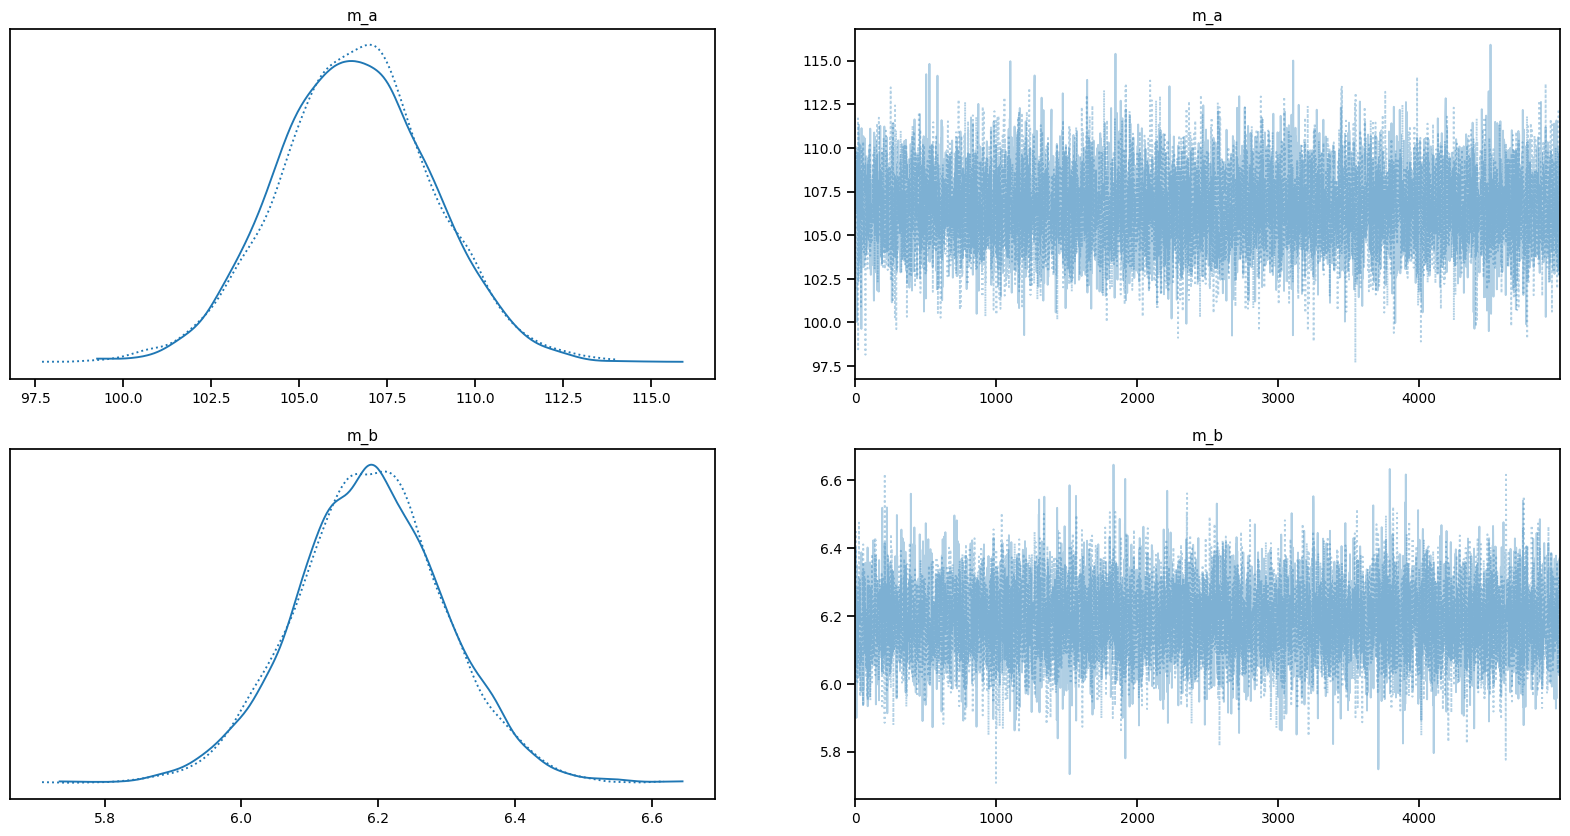

In [28]:
az.plot_trace(rat_trace, var_names=['m_a', 'm_b'],figsize=(20,10))

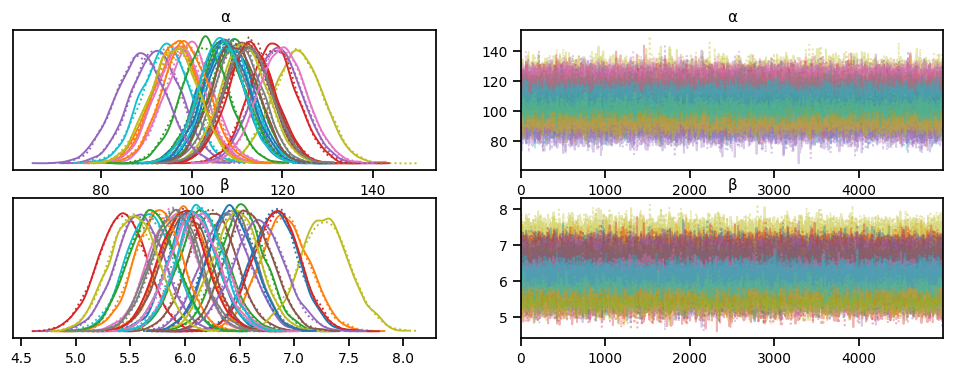

In [29]:
az.plot_trace(rat_trace, var_names=['α', 'β']);

### Informal Methods

The most straightforward approach for assessing convergence is based on
simply **plotting and inspecting traces and histograms** of the observed
MCMC sample, as was done in the cell above. If the trace of values for each of the stochastics exhibits
asymptotic behavior over the last $m$ iterations, this may be
satisfactory evidence for convergence.

In [30]:

with rat_model:
    trace_bad = pm.sample(1000, start={'m_a': 1000, 'm_b': -10}, step=pm.Metropolis(), cores=2)

Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


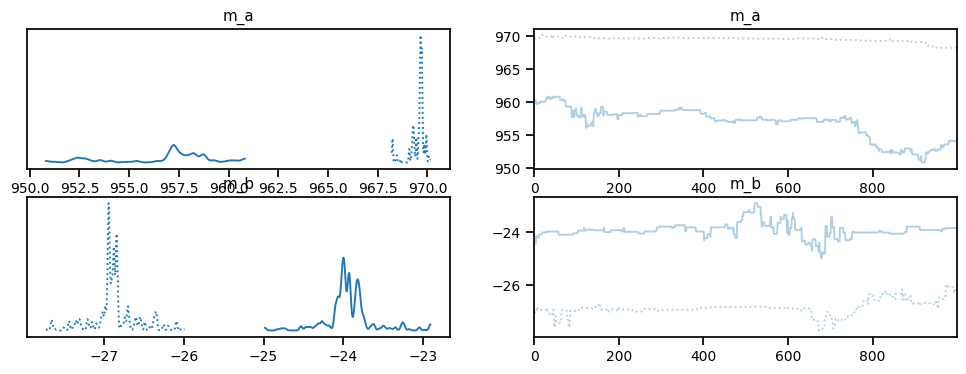

In [31]:
az.plot_trace(trace_bad, var_names=['m_a', 'm_b']);

Another *ad hoc* method for detecting lack of convergence is to examine
the traces of several MCMC chains **initialized with different starting
values**. Overlaying these traces on the same set of axes should (if
convergence has occurred) show each chain tending toward the same
equilibrium value, with approximately the same variance. Recall that the
tendency for some Markov chains to converge to the true (unknown) value
from diverse initial values is called *ergodicity*. This property is
guaranteed by the reversible chains constructed using MCMC, and should
be observable using this technique. Again, however, this approach is
only a heuristic method, and cannot always detect lack of convergence,
even though chains may appear ergodic.

In [32]:

with rat_model:

    tr = pm.sample(250, cores=2, start=[{'m_a':100}, {'m_a':180}], discard_tuned_samples=False, random_seed=1, return_inferencedata=False)

Output()

In [33]:
tr.get_values('m_a', chains=0)

array([100.81638643, 100.81638643, 100.81638643, ..., 106.24270875,
       108.38969814, 109.16262239])

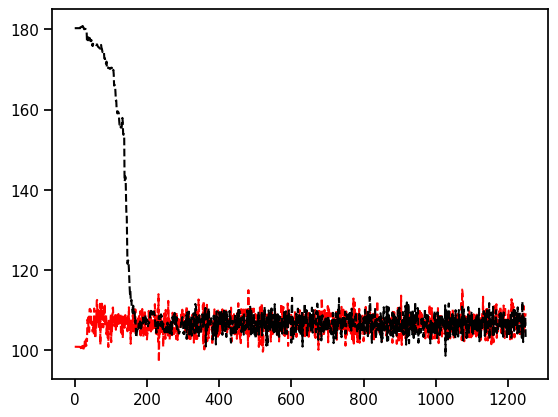

In [34]:
plt.plot(tr.get_values('m_a', chains=0), 'r--')
plt.plot(tr.get_values('m_a', chains=1), 'k--')

A principal reason that evidence from informal techniques cannot
guarantee convergence is a phenomenon called ***metastability***. Chains may
appear to have converged to the true equilibrium value, displaying
excellent qualities by any of the methods described above. However,
after some period of stability around this value, the chain may suddenly
move to another region of the parameter space. This period
of metastability can sometimes be very long, and therefore escape
detection by these convergence diagnostics. Unfortunately, there is no
statistical technique available for detecting metastability.

### Formal Methods

Along with the *ad hoc* techniques described above, a number of more
formal methods exist which are prevalent in the literature. These are
considered more formal because they are based on existing statistical
methods, such as time series analysis.

PyMC and ArviZ currently include a handful formal convergence diagnostic methods.  A commonly-applied metric is the Gelman-Rubin statistic [Gelman and Rubin (1992)](http://projecteuclid.org/DPubS?service=UI&version=1.0&verb=Display&handle=euclid.ss/1177011136). This diagnostic uses multiple chains to check for lack of convergence, and is based on the notion that if multiple chains have converged, by definition they should appear very similar to one another; if not, one or more of the chains has failed to
converge.

The Gelman-Rubin diagnostic uses an analysis of variance approach to assessing convergence. That is, it calculates both the between-chain varaince (B) and within-chain varaince (W), and assesses whether they are different enough to worry about convergence. Assuming $m$ chains, each of length $n$, quantities are calculated by:

$$\begin{align}B &= \frac{n}{m-1} \sum_{j=1}^m (\bar{\theta}_{.j} - \bar{\theta}_{..})^2 \\
W &= \frac{1}{m} \sum_{j=1}^m \left[ \frac{1}{n-1} \sum_{i=1}^n (\theta_{ij} - \bar{\theta}_{.j})^2 \right]
\end{align}$$

for each scalar estimand $\theta$. Using these values, an estimate of the marginal posterior variance of $\theta$ can be calculated:

$$\hat{\text{Var}}(\theta | y) = \frac{n-1}{n} W + \frac{1}{n} B$$

Assuming $\theta$ was initialized to arbitrary starting points in each chain, this quantity will overestimate the true marginal posterior variance. At the same time, $W$ will tend to underestimate the
within-chain variance early in the sampling run. However, in the limit as $n \rightarrow  \infty$, both quantities will converge to the true variance of $\theta$. In light of this, the Gelman-Rubin statistic monitors convergence using the ratio:

$$\hat{R} = \sqrt{\frac{\hat{\text{Var}}(\theta | y)}{W}}$$

This is called the potential scale reduction, since it is an estimate of the potential reduction in the scale of $\theta$ as the number of simulations tends to infinity. In practice, we look for values of $\hat{R}$ close to one (say, less than 1.1) to be confident that a particular estimand has converged. In PyMC, the function `gelman_rubin` will calculate $\hat{R}$ for each stochastic node in the passed model:

## Lets check r_hat results

In [ ]:
az.summary(rat_trace)

## Autocorrelation

**Definition:**  
Autocorrelation measures the similarity between values of a time series (or sequence) at different points in time. For a given lag \( k \), it quantifies the linear relationship between the values at time \( t \) and time \( t + k \).

**Mathematical Formulation:**  
The autocorrelation function $ \rho(k) $ for a sequence $ \{x_t\} $ is defined as:

$$
\rho(k) = \frac{\mathrm{Cov}(x_t, x_{t+k})}{\sqrt{\mathrm{Var}(x_t)\mathrm{Var}(x_{t+k})}}
$$



where:
- $ \mu $ is the mean of the series,
- $ \sigma^2 $ is the variance,
- $ \mathbb{E} $ is the expectation operator.

## Autocorrelation



In general, samples drawn from MCMC algorithms will be autocorrelated. This is not a big deal, other than the fact that autocorrelated chains may require longer sampling in order to adequately characterize posterior quantities of interest. The calculation of autocorrelation is performed for each lag $i=1,2,\ldots,k$ (the correlation at lag 0 is, of course, 1) by:

$$\hat{\rho}_i = 1 - \frac{V_i}{2\hat{\text{Var}}(\theta | y)}$$

where $\hat{\text{Var}}(\theta | y)$ is the same estimated variance as calculated for the Gelman-Rubin statistic, and $V_i$ is the variogram at lag $i$ for $\theta$:

$$\text{V}_i = \frac{1}{m(n-i)}\sum_{j=1}^m \sum_{k=i+1}^n (\theta_{jk} - \theta_{j(k-i)})^2$$

This autocorrelation can be visualized using the `plot_autocorr` function in ArviZ or PyMC:

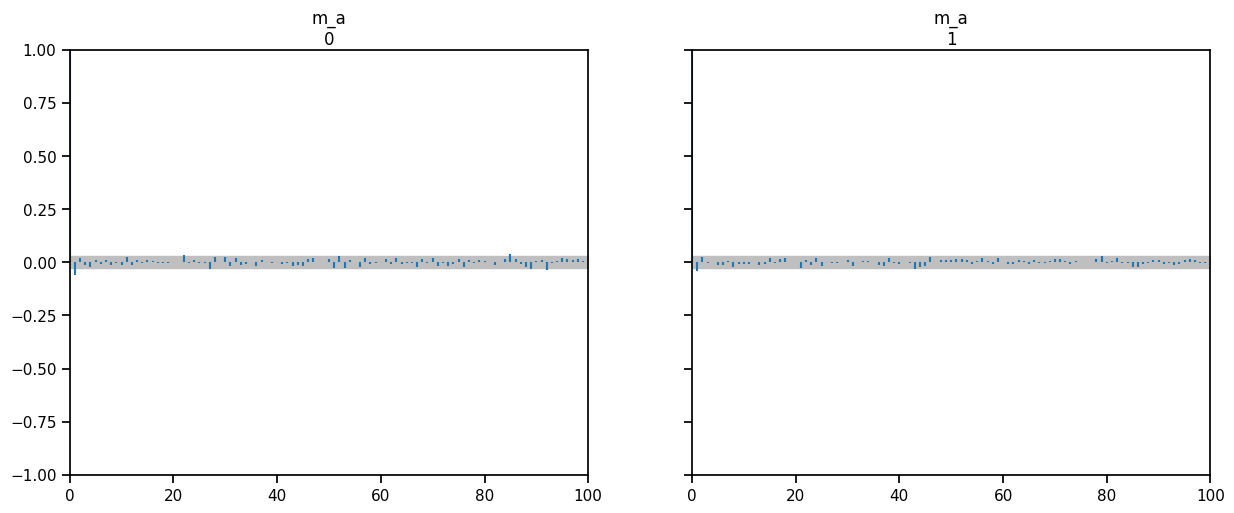

In [35]:
from arviz import plot_autocorr

plot_autocorr(rat_trace, var_names=['m_a']);

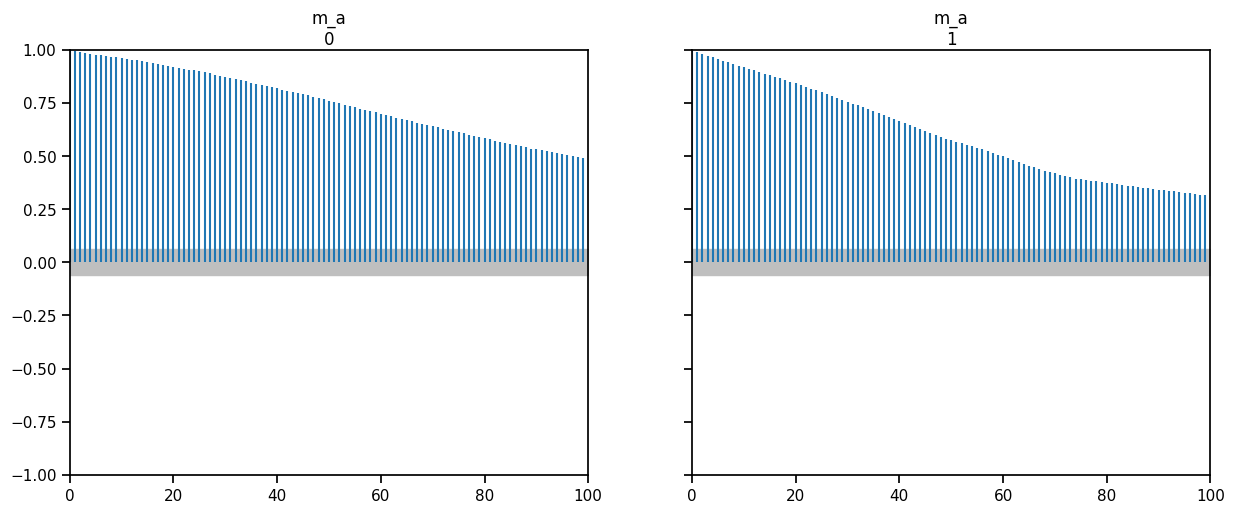

In [36]:
plot_autocorr(trace_bad, var_names=['m_a']);

### Effective sample size

The main concern with high autocorrelation is that the effective sample size of the resulting chain can be greatly reduced. Hence, it will take more draws to control sampling variation, relative to a less correlated sample.

The effective sample size is estimated using the partial sum:

$$\hat{n}_{eff} = \frac{mn}{1 + 2\sum_{i=1}^T \hat{\rho}_i}$$

where $T$ is the first odd integer such that $\hat{\rho}_{T+1} + \hat{\rho}_{T+2}$ is negative.

The issue here is related to the fact that we are **estimating** the effective sample size from the fit output. Values of $n_{eff} / n_{iter} < 0.001$ indicate a biased estimator, resulting in an overestimate of the true effective sample size.

In [37]:

ess = az.ess(rat_trace)
print(ess)

<xarray.Dataset> Size: 760B
Dimensions:     (rats_names: 30)
Coordinates:
  * rats_names  (rats_names) int64 240B 0 1 2 3 4 5 6 7 ... 23 24 25 26 27 28 29
Data variables:
    m_a         float64 8B 1.081e+04
    m_b         float64 8B 1.049e+04
    s_a         float64 8B 7.011e+03
    s_b         float64 8B 8.891e+03
    α           (rats_names) float64 240B 1.167e+04 1.182e+04 ... 1.261e+04
    β           (rats_names) float64 240B 1.117e+04 1.175e+04 ... 1.207e+04
    σ           float64 8B 6.306e+03


Effective sample size estimates can optionally be added to forest plots.

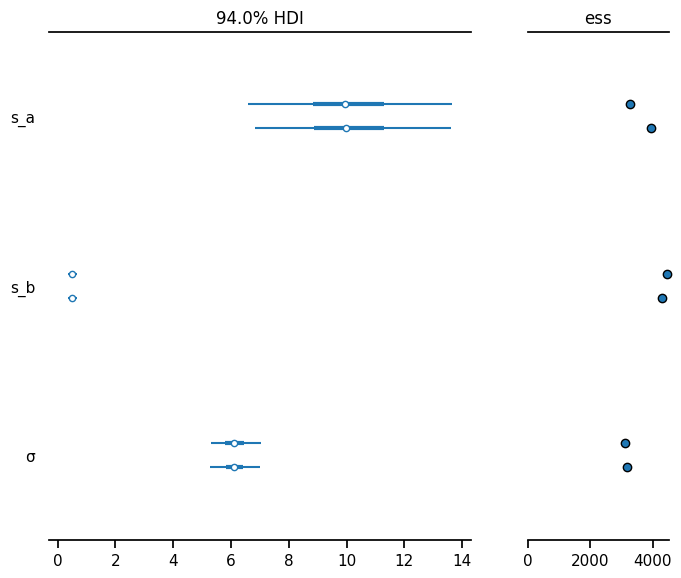

In [39]:
az.plot_forest(rat_trace, var_names=['s_a', 's_b', 'σ'], ess=True);

Both low $n_{eff}$ and high $\hat{R}$ indicate **poor mixing**.

It is tempting to want to **thin** the chain to eliminate the autocorrelation (*e.g.* taking every 20th sample from the traces above), but this is a waste of time. Since thinning deliberately throws out the majority of the samples, no efficiency is gained; you ultimately require more samples to achive a particular desired sample size.